# Гибридная выдача и итоговый эксперимент

Финальная система объединяет несколько источников рекомендаций, согласует их порядок, формирует набор кандидатов и применяет правила состава списка. Изученные алгоритмы используются без повторного вывода их формул.

В содержательном алгоритме зафиксированы полураспад 90 дней и отсутствие ценового штрафа, в ALS — rank=16, regularization=1, alpha=5, восемь итераций. Эти параметры выбраны по апрелю в предыдущих файлах. Item-item настраивается по той же апрельской сетке. Май остаётся финальным периодом.

Ни один результат не гарантирует преимущество гибрида: содержательный вес 1 и коллаборативный вес 1 включены в сравнение. Усложнение сохраняется только при понятной пользе или явном требовании к выдаче.

## Общий эксперимент и сопоставимость источников

Алгоритмы возвращают оценки разных масштабов. Популярность — число покупателей, содержательный скоринг — сходство с профилем, ALS — произведение факторов. Прямое сложение этих чисел без согласования масштаба задаёт случайное преимущество одному источнику.

Повторное использование настроек из предыдущих экспериментов не делает validation независимым финальным тестом. Накопленное число решений повышает риск подгонки по апрелю; контрольный май служит отдельной проверкой.

Файл независим от состояния памяти предыдущих ноутбуков. Включённые функции и CSV достаточны для расчёта. Границы истории и контрольного периода не меняются при переходе к гибридному алгоритму.

In [1]:
# Шаг М4.05.01 — Среда и единый договор оценки
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
from sklearn.preprocessing import normalize
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.decomposition import TruncatedSVD
from IPython.display import display

pd.set_option("display.max_colwidth", 90)
plt.rcParams.update({"figure.figsize": (9, 4), "font.size": 10})
module_name = "Модуль 4 Рекомендательные системы"
candidates = [candidate for root in [Path.cwd(), *Path.cwd().parents]
              for candidate in (root, root / "course" / "practice" / module_name)]
MODULE_DIR = next(p for p in candidates if p.name == module_name and p.is_dir())
DATA_DIR = MODULE_DIR / "data"
SOURCE_DIR = MODULE_DIR.parent.parent / "data"
print("Каталог материалов:", MODULE_DIR.name)

import json


def load_context(phase="validation"):
    if phase not in {"validation", "test"}:
        raise ValueError("Ожидается validation или test")
    catalog = pd.read_csv(DATA_DIR / "reco_catalog.csv").sort_values("product_id").reset_index(drop=True)
    events = pd.read_csv(DATA_DIR / "reco_events.csv", parse_dates=["timestamp"]).drop_duplicates("event_id")
    cut = pd.Timestamp("2025-04-01" if phase == "validation" else "2025-05-01")
    end = pd.Timestamp("2025-05-01" if phase == "validation" else "2025-06-01")
    history = events[events.timestamp < cut].copy()
    future = events[(events.timestamp >= cut) & (events.timestamp < end) & (events.event_type == "purchase")]
    user_ids = np.arange(1, 301)  # Известный учебный реестр, а не признак предпочтения.
    item_ids = catalog.product_id.to_numpy()
    u_map = {int(value): index for index, value in enumerate(user_ids)}
    i_map = {int(value): index for index, value in enumerate(item_ids)}
    history["strength"] = history.event_type.map({"view": 1.0, "cart": 3.0, "purchase": 5.0})
    pairs = history.groupby(["user_id", "product_id"]).strength.sum().reset_index()
    R = sparse.csr_matrix((np.log1p(pairs.strength),
                           (pairs.user_id.map(u_map), pairs.product_id.map(i_map))),
                          shape=(len(user_ids), len(item_ids)))
    B = R.copy()
    B.data[:] = 1.0
    seen = B.toarray().astype(bool)  # Только 300 x 180; полный большой каталог так не разворачивается.
    truth = {int(u): set(g.product_id) - set(item_ids[seen[u_map[int(u)]]])
             for u, g in future.groupby("user_id")}
    purchases = history[history.event_type.eq("purchase")].drop_duplicates(["user_id", "product_id"])
    popularity = purchases.groupby("product_id").size().reindex(item_ids, fill_value=0).to_numpy(float)
    return dict(catalog=catalog, events=events, history=history, R=R, B=B, seen=seen,
                truth=truth, user_ids=user_ids, item_ids=item_ids, u_map=u_map,
                i_map=i_map, popularity=popularity, cut=cut, end=end, phase=phase)

def top_indices(scores, seen, k=10):
    values = np.array(scores, dtype=float, copy=True)
    if values.ndim != 2 or values.shape != seen.shape or not np.isfinite(values).all():
        raise ValueError("Нужна конечная матрица оценок формы user x item")
    values[seen] = -np.inf
    result = []
    for row in values:
        order = np.argsort(-row, kind="stable")
        result.append(order[np.isfinite(row[order])][:k])
    return result

def evaluate(scores, ctx, k=10):
    ranked = top_indices(scores, ctx["seen"], k)
    rows = []
    for u, relevant in ctx["truth"].items():
        if not relevant:
            continue
        ui = ctx["u_map"][u]
        recommended = ctx["item_ids"][ranked[ui]]
        hits = np.isin(recommended, list(relevant)).astype(float)
        discounts = 1 / np.log2(np.arange(2, len(hits) + 2))
        ideal = (1 / np.log2(np.arange(2, min(k, len(relevant)) + 2))).sum()
        positions = np.flatnonzero(hits)
        rows.append(dict(user_id=u, history_size=int(ctx["seen"][ui].sum()), n_truth=len(relevant),
                         precision=float(hits.sum()/k), recall=float(hits.sum()/len(relevant)),
                         ndcg=float(hits @ discounts / ideal), hit=float(hits.any()),
                         mrr=0.0 if not len(positions) else 1.0/(positions[0]+1)))
    return pd.DataFrame(rows)

def summarize(scores, ctx, k=10):
    detail = evaluate(scores, ctx, k)
    ranked = top_indices(scores, ctx["seen"], k)
    evaluated_rows = [ranked[ctx["u_map"][int(u)]] for u in detail.user_id]
    chosen = np.concatenate(evaluated_rows)
    novelty = -np.log2((ctx["popularity"]+1)/(ctx["popularity"].sum()+len(ctx["item_ids"])))
    return pd.Series({"Precision@K":detail.precision.mean(), "Recall@K":detail.recall.mean(),
                      "NDCG@K":detail.ndcg.mean(), "HitRate@K":detail.hit.mean(),
                      "Coverage":len(np.unique(chosen))/len(ctx["item_ids"]),
                      "Novelty":float(novelty[chosen].mean()), "users":len(detail)})

def popular_scores(ctx):
    return np.tile(ctx["popularity"], (len(ctx["user_ids"]), 1))

Каталог материалов: Модуль 4 Рекомендательные системы


Реализации в этой ячейке повторяют вычисления прежних файлов; новая тема начинается с объединения их результатов. Ни один алгоритм не получает флаг будущей покупки как входной признак.

In [2]:
# Шаг М4.05.02 — Функции уже изученных моделей
def fit_content(ctx, half_life=None, price_penalty=0.0):
    catalog = ctx["catalog"]
    documents = catalog.category + " " + catalog.collection + " " + catalog.usage
    vectorizer = TfidfVectorizer(token_pattern=r"(?u)\b\w+\b")
    F = vectorizer.fit_transform(documents)
    hist = ctx["history"].copy()
    strength = hist.strength.to_numpy()
    if half_life is not None:
        age = (ctx["cut"] - hist.timestamp).dt.total_seconds().to_numpy()/86400
        strength = strength * np.exp2(-age/half_life)
    hist["weighted"] = strength
    pairs = hist.groupby(["user_id","product_id"]).weighted.sum().reset_index()
    Rw = sparse.csr_matrix((np.log1p(pairs.weighted),
                           (pairs.user_id.map(ctx["u_map"]),pairs.product_id.map(ctx["i_map"]))),
                          shape=ctx["R"].shape)
    profiles = normalize(Rw @ F)
    scores = (profiles @ F.T).toarray()
    denominator = np.asarray(Rw.sum(axis=1)).ravel()
    log_price = np.log1p(catalog.price.to_numpy())
    typical = np.divide(np.asarray(Rw @ log_price).ravel(),denominator,
                        out=np.zeros_like(denominator),where=denominator>0)
    scores -= price_penalty*np.abs(typical[:,None]-log_price[None,:])
    cold = denominator==0
    scores[cold] = ctx["popularity"]
    return dict(scores=scores,F=F,profiles=profiles,vectorizer=vectorizer,
                weighted_history=Rw,half_life=half_life,price_penalty=price_penalty)


def item_knn_scores(ctx, neighbors=20, shrink=5.0):
    B = ctx["B"]
    counts = np.asarray(B.sum(axis=0)).ravel()
    co = (B.T @ B).toarray()
    denominator = np.sqrt(np.outer(counts, counts))
    similarity = np.divide(co, denominator, out=np.zeros_like(co), where=denominator>0)
    similarity *= np.divide(co,co+shrink,out=np.zeros_like(co),where=(co+shrink)>0)
    np.fill_diagonal(similarity, 0)
    selected = np.zeros_like(similarity)
    for i, row in enumerate(similarity):
        idx = np.argsort(-row, kind="stable")[:neighbors]
        selected[i, idx] = row[idx]
    scores = np.asarray(ctx["R"] @ selected)
    # S_ij задаёт переход из исторического i к кандидату j; строки обрезаны до соседей.
    cold = np.asarray(B.sum(axis=1)).ravel() == 0
    scores[cold] = ctx["popularity"]
    return scores, selected


def als_fit(ctx, rank=16, regularization=0.1, alpha=15.0, iterations=10, seed=42):
    """Обучение учебной implicit ALS на небольшом наборе взаимодействий."""
    if rank < 1 or regularization <= 0 or alpha < 0 or iterations < 1:
        raise ValueError("Проверьте ранг, регуляризацию, alpha и число итераций")
    R = ctx["R"].toarray()
    P = (R > 0).astype(float)
    n_users, n_items = R.shape
    rng = np.random.default_rng(seed)
    X = np.zeros((n_users, rank))
    Y = rng.normal(0, 0.1, size=(n_items, rank))
    eye = np.eye(rank)
    losses = []

    for _ in range(iterations):
        yty = Y.T @ Y
        for u in range(n_users):
            observed = np.flatnonzero(P[u])
            if not len(observed):
                X[u] = 0.0
                continue
            factors = Y[observed]
            confidence = 1.0 + alpha * R[u, observed]
            lhs = yty + factors.T @ ((confidence - 1.0)[:, None] * factors)
            X[u] = np.linalg.solve(lhs + regularization * eye,
                                   factors.T @ confidence)

        xtx = X.T @ X
        for i in range(n_items):
            observed = np.flatnonzero(P[:, i])
            if not len(observed):
                Y[i] = 0.0
                continue
            factors = X[observed]
            confidence = 1.0 + alpha * R[observed, i]
            lhs = xtx + factors.T @ ((confidence - 1.0)[:, None] * factors)
            Y[i] = np.linalg.solve(lhs + regularization * eye,
                                   factors.T @ confidence)

        residual = P - X @ Y.T
        loss = np.square(residual).sum()
        loss += alpha * (R * np.square(residual)).sum()
        loss += regularization * (np.square(X).sum() + np.square(Y).sum())
        losses.append(float(loss))

    return {"user_factors": X, "item_factors": Y, "loss": losses,
            "rank": rank, "regularization": regularization, "alpha": alpha}


def als_scores(model, ctx):
    """Оценки известных пар и популярность для пользователей без истории."""
    scores = model["user_factors"] @ model["item_factors"].T
    if scores.shape != ctx["seen"].shape:
        raise ValueError("Размер факторов не соответствует контексту")
    cold = np.asarray(ctx["B"].sum(axis=1)).ravel() == 0
    scores[cold] = ctx["popularity"]
    return scores

Апрель используется повторно для настройки и объединения алгоритмов. Поэтому его числа показывают результат выбора на validation, а не независимую оценку обобщения. Финальная проверка проводится после фиксации всех правил.

У всех компонентов сохранены общие границы времени, кандидаты и метрики. Повторная настройка по одному периоду увеличивает число принятых по нему решений. Поэтому небольшой выигрыш в этой таблице требует отдельной последующей проверки.

In [3]:
# Шаг М4.05.03 — Выбор соседской конфигурации по апрелю
ctx=load_context("validation")
knn_grid=[]
for neighbors in [5,10,20,40]:
    for shrink in [0.0,5.0,20.0]:
        score,_=item_knn_scores(ctx,neighbors,shrink)
        metrics=summarize(score,ctx)
        knn_grid.append({"neighbors":neighbors,"shrink":shrink,**metrics.to_dict()})
knn_grid=pd.DataFrame(knn_grid).sort_values(["NDCG@K","Recall@K"],ascending=False,kind="stable")
knn_params={"neighbors":int(knn_grid.iloc[0].neighbors),"shrink":float(knn_grid.iloc[0].shrink)}
display(knn_grid[["neighbors","shrink","NDCG@K","Recall@K"]].head(5).round(4))
print("Зафиксировано:",knn_params)

,neighbors,shrink,NDCG@K,Recall@K
6,20,0.0,0.2250,0.2828
9,40,0.0,0.2194,0.2810
7,20,5.0,0.2098,0.2629
10,40,5.0,0.2018,0.2560
8,20,20.0,0.1943,0.2457


Зафиксировано: {'neighbors': 20, 'shrink': 0.0}


Каждая матрица имеет один порядок пользователей и товаров. Коллаборативный источник выбирается только среди item-item и ALS; содержательная модель не участвует в этом внутреннем выборе, поскольку образует вторую часть смеси.

Внутренний выбор коллаборативного источника предшествует настройке веса. Он не использует май и не изменяет состав оцениваемой аудитории. Все результаты по-прежнему относятся к одному синтетическому журналу.

In [4]:
# Шаг М4.05.04 — Банк оценок и содержательные признаки
def reciprocal_ranks(scores, seen, offset=60.0):
    result=np.zeros_like(scores,dtype=float)
    for u, indices in enumerate(top_indices(scores,seen,scores.shape[1])):
        result[u,indices]=1/(offset+np.arange(1,len(indices)+1))
    return result

def fuse(content, collaborative, ctx, content_weight):
    return (content_weight*reciprocal_ranks(content,ctx["seen"])
            +(1-content_weight)*reciprocal_ranks(collaborative,ctx["seen"]))

def build_bank(ctx, knn_params):
    content=fit_content(ctx,half_life=90,price_penalty=0.0)
    knn=item_knn_scores(ctx,**knn_params)[0]
    als=als_fit(ctx,rank=16,regularization=1.0,alpha=5.0,iterations=8,seed=42)
    return {"популярность":popular_scores(ctx),"содержание":content["scores"],
            "item-item":knn,"ALS":als_scores(als,ctx)},content["F"]

bank,F=build_bank(ctx,knn_params)
assert all(score.shape==ctx["R"].shape for score in bank.values())
validation_table=pd.DataFrame({name:summarize(score,ctx) for name,score in bank.items()}).T
display(validation_table.round(4))
cf_name=validation_table.loc[["item-item","ALS"],"NDCG@K"].astype(float).idxmax()
print("Коллаборативный источник смеси:",cf_name)

,Precision@K,Recall@K,NDCG@K,HitRate@K,Coverage,Novelty,users
популярность,0.0303,0.0759,0.0608,0.2724,0.1000,6.4356,290.0
содержание,0.1262,0.3155,0.2658,0.8034,1.0000,7.8392,290.0
item-item,0.1131,0.2828,0.2250,0.7759,0.9389,7.3989,290.0
ALS,0.0838,0.2095,0.1617,0.6345,0.9500,7.3496,290.0


Коллаборативный источник смеси: item-item


Согласование по рангу теряет информацию о расстоянии между исходными оценками. Такой выбор устойчив к монотонному изменению масштаба, но сильное и слабое преимущество соседних объектов будут различаться только их местами.

Прямое среднее разных оценок могло бы зависеть от произвольной единицы измерения. Преобразование в ранги устраняет эту зависимость ценой потери информации о расстоянии между соседними исходными оценками.

In [5]:
# Шаг М4.05.05 — Различие масштабов оценок
ui=ctx["u_map"][1]
available=~ctx["seen"][ui]
display(pd.DataFrame({name:pd.Series(score[ui,available]).describe()[["min","50%","max"]]
                      for name,score in bank.items()}).T)

,min,50%,max
популярность,0.000000,7.500000,22.000000
содержание,0.109995,0.245867,0.690457
item-item,0.000000,0.283760,4.133786
ALS,-0.458387,0.082607,0.899749


Компоненты сопоставлены на одном протоколе; их разные масштабы явно отделены от качества порядка. Выбран коллаборативный источник для последующего объединения.

## Объединение рангов и контроль гибрида

Weighted reciprocal rank fusion присваивает объекту вклад w/(c+rank_content) + (1−w)/(c+rank_cf). Здесь c=60, ранги начинаются с единицы и считаются только по допустимым кандидатам. Исторические объекты получают нулевой вклад и всё равно исключаются общей маской.

Вес w выбирается из заранее заданной сетки по NDCG@10 на validation. Крайние значения сохраняют вариант одного источника и не позволяют объявить смесь полезной без сравнения.

Выбор веса использует одинаковую метрику и одинаковое K для всех строк. Если выиграл крайний вес, дополнительный источник не улучшил выбранный критерий. Это допустимый результат сравнения.

Параметр веса относится к объединению двух порядков. Он не меняет признаки и не переобучает компоненты. Крайние значения необходимы как контроль отсутствия полезного вклада второго источника.

In [6]:
# Шаг М4.05.06 — Сетка весов гибрида
fusion_grid=[]
for weight in [0.0,.25,.5,.75,1.0]:
    score=fuse(bank["содержание"],bank[cf_name],ctx,weight)
    fusion_grid.append({"content_weight":weight,**summarize(score,ctx).to_dict()})
fusion_grid=pd.DataFrame(fusion_grid).sort_values("NDCG@K",ascending=False,kind="stable")
display(fusion_grid.round(4))
weight=float(fusion_grid.iloc[0].content_weight)
fused=fuse(bank["содержание"],bank[cf_name],ctx,weight)

,content_weight,Precision@K,Recall@K,NDCG@K,HitRate@K,Coverage,Novelty,users
4,1.00,0.1262,0.3155,0.2658,0.8034,1.0000,7.8392,290.0
2,0.50,0.1176,0.2940,0.2368,0.7793,0.9500,7.5130,290.0
3,0.75,0.1138,0.2845,0.2349,0.7690,0.9722,7.5618,290.0
1,0.25,0.1169,0.2922,0.2311,0.7931,0.9444,7.4665,290.0
0,0.00,0.1131,0.2828,0.2250,0.7759,0.9389,7.3989,290.0


Кривая относится к выбранному синтетическому журналу. Она не задаёт универсальное соотношение содержания и поведения. Последующие правила состава списка рассматриваются отдельно от этого веса.

Положение максимума относится к данной сетке и валидационной выборке. Оно не даёт основания объявлять универсальную пропорцию сигналов. Проверка устойчивости потребовала бы дополнительных периодов и пользователей.

,зафиксировано
источник CF,item-item
вес содержания,1.0
вес CF,0.0
K,10
offset,60
период выбора,апрель


,объединённый порядок
Precision@K,0.1262
Recall@K,0.3155
NDCG@K,0.2658
HitRate@K,0.8034
Coverage,1.0000
Novelty,7.8392
users,290.0000


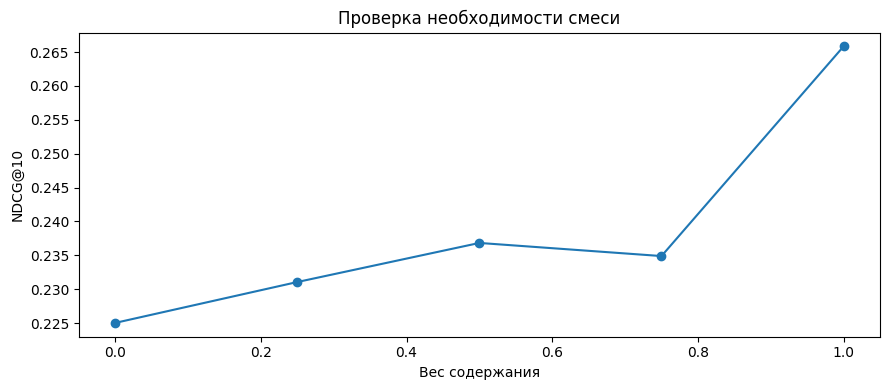

In [7]:
# Шаг М4.05.07 — Выбранный вес и его результат
display(pd.Series({"источник CF":cf_name,"вес содержания":weight,"вес CF":1-weight,
                   "K":10,"offset":60,"период выбора":"апрель"}).to_frame("зафиксировано"))
display(summarize(fused,ctx).round(4).to_frame("объединённый порядок"))
fusion_grid.sort_values("content_weight").plot(x="content_weight",y="NDCG@K",marker="o",legend=False)
plt.xlabel("Вес содержания");plt.ylabel("NDCG@10");plt.title("Проверка необходимости смеси")
plt.tight_layout();plt.show()

Сумма вкладов точно восстанавливает объединённую оценку. Разложение относится к скорингу до последующего ограничения кандидатов и изменения порядка ради состава списка.

Вклады относятся к этапу скоринга. После ограничений состава список может измениться, поэтому объяснение финального места должно учитывать и последующие правила, а не только сумму источников.

In [8]:
# Шаг М4.05.08 — Проверяемые вклады двух источников
a=reciprocal_ranks(bank["содержание"],ctx["seen"])
b=reciprocal_ranks(bank[cf_name],ctx["seen"])
idx=top_indices(fused,ctx["seen"],10)[ui]
display(ctx["catalog"].iloc[idx][["product_id","category"]].assign(
    вклад_содержания=weight*a[ui,idx],вклад_CF=(1-weight)*b[ui,idx],сумма=fused[ui,idx]))
assert np.allclose(fused,weight*a+(1-weight)*b)

,product_id,category,вклад_содержания,вклад_CF,сумма
37,38,Продукты,0.016393,0.0,0.016393
114,119,Продукты,0.016129,0.0,0.016129
19,20,Продукты,0.015873,0.0,0.015873
98,101,Продукты,0.015625,0.0,0.015625
42,43,Продукты,0.015385,0.0,0.015385
38,39,Продукты,0.015152,0.0,0.015152
115,120,Продукты,0.014925,0.0,0.014925
63,64,Продукты,0.014706,0.0,0.014706
6,7,Продукты,0.014493,0.0,0.014493
72,73,Продукты,0.014286,0.0,0.014286


Вес смеси выбран и зафиксирован по апрелю. Наличие гибридной формулы не подменяет проверку полезности: отдельные источники остаются полноценными участниками сравнения.

## Кандидаты и разнообразие итогового списка

Двухэтапная схема сначала быстро собирает ограниченный пул кандидатов, затем ранжирует его более подробно. Candidate Recall — доля контрольных покупок, попавших в пул. Это верхняя граница достижимой Recall итогового списка при данном пуле.

MMR при выборе очередного объекта объединяет его релевантность с наказанием за близость к уже выбранным. Дополнительно применяется ограничение: не более трёх товаров одной категории. Это явная политика состава списка, а не доказанный оптимум бизнес-эффекта.

Учебная реализация рассчитывает сходство всех 180 товаров. На большом каталоге требуется считать его только для текущего пула или хранить подходящее представление для быстрых запросов. Полная квадратная матрица не является масштабируемым решением.

Двухэтапная схема имеет два разных источника потерь: полезный объект может не попасть в пул либо оказаться низко уже внутри него. Измерение полноты кандидатов позволяет отделить эти причины.

In [9]:
# Шаг М4.05.09 — Функции кандидатов и формирования списка
def candidate_pools(ctx, sources, per_source=30):
    ranked=[top_indices(source,ctx["seen"],per_source) for source in sources]
    return [np.unique(np.concatenate([r[u] for r in ranked])) for u in range(len(ctx["user_ids"]))]

def candidate_recall(pools,ctx):
    return pd.Series({u:len(set(ctx["item_ids"][pools[ctx["u_map"][u]]])&relevant)/len(relevant)
                      for u,relevant in ctx["truth"].items() if relevant},name="candidate_recall")

def rerank_row(raw_scores, pool, catalog, similarity, k=10, relevance_weight=.9, category_cap=3):
    pool=np.asarray(pool,dtype=int)
    if len(pool)==0:
        return []
    values=raw_scores[pool]
    span=values.max()-values.min()
    relevance=np.zeros(len(raw_scores))
    relevance[pool]=(values-values.min())/span if span>0 else 0.0
    selected=[]
    counts={}
    remaining=set(map(int,pool))
    while remaining and len(selected)<k:
        feasible=[i for i in sorted(remaining)
                  if counts.get(catalog.category.iloc[i],0)<category_cap]
        if not feasible:
            break
        def objective(i):
            redundancy=max(similarity[i,selected]) if selected else 0.0
            return relevance_weight*relevance[i]-(1-relevance_weight)*redundancy
        best=max(feasible,key=lambda i:(objective(i),-i))
        selected.append(best)
        category=catalog.category.iloc[best]
        counts[category]=counts.get(category,0)+1
        remaining.remove(best)
    return selected

def pipeline_lists(ctx,scores,F,sources,per_source=30):
    pools=candidate_pools(ctx,sources,per_source)
    similarity=(F@F.T).toarray()
    lists=[rerank_row(scores[u],pool,ctx["catalog"],similarity)
           for u,pool in enumerate(pools)]
    return lists,pools

def lists_as_scores(lists,ctx):
    if any(len(indices)!=10 for indices in lists):
        raise ValueError("Для общей оценки ожидаются полные списки из 10 товаров")
    result=np.full(ctx["R"].shape,-1e6)
    for u,indices in enumerate(lists):
        result[u,indices]=np.arange(len(indices),0,-1)
    return result

def list_diversity(lists,F):
    similarity=(F@F.T).toarray()
    values=[]
    for indices in lists:
        if len(indices)<2:
            continue
        block=similarity[np.ix_(indices,indices)]
        values.append(1-block[np.triu_indices(len(indices),1)].mean())
    return float(np.mean(values))

Зависимость Candidate Recall от размера пула показывает компромисс между вычислением и потенциальным качеством. Она не использует тест для настройки: в итоговой политике заранее фиксируются 30 кандидатов от каждого источника.

Увеличение числа кандидатов расширяет потенциальные возможности ранжировщика, но требует дополнительной работы. При большом каталоге размер и задержка вычислений становятся частью требований к системе, а не только вопросом качества.

,на источник,средний пул,Candidate Recall
0,5,7.6167,0.2672
1,10,13.1633,0.3784
2,20,28.0933,0.5009
3,30,42.7467,0.6026
4,60,82.2933,0.7862


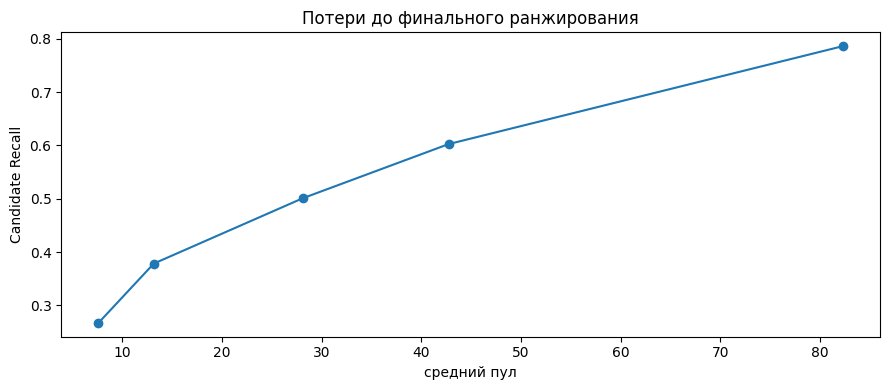

In [10]:
# Шаг М4.05.10 — Полнота разных пулов кандидатов
pool_checks=[]
for size in [5,10,20,30,60]:
    pools=candidate_pools(ctx,[bank["содержание"],bank[cf_name]],size)
    pool_checks.append({"на источник":size,"средний пул":np.mean([len(p) for p in pools]),
                        "Candidate Recall":candidate_recall(pools,ctx).mean()})
pool_checks=pd.DataFrame(pool_checks)
display(pool_checks.round(4))
pool_checks.plot(x="средний пул",y="Candidate Recall",marker="o",legend=False)
plt.title("Потери до финального ранжирования");plt.ylabel("Candidate Recall")
plt.tight_layout();plt.show()

Политика: 30 объектов от каждого из двух источников, объединение без дубликатов, MMR с весом релевантности 0.9, не более трёх товаров одной категории. Эти правила зафиксированы до майской проверки.

Последовательный выбор MMR зависит от ранее выбранных объектов. Он не обязан совпадать с одной глобальной сортировкой. При равенстве сохраняется однозначное техническое правило выбора, чтобы выдача воспроизводилась.

In [11]:
# Шаг М4.05.11 — Одна выдача после изменения состава списка
lists,pools=pipeline_lists(ctx,fused,F,[bank["содержание"],bank[cf_name]])
assert all(len(indices)==10 for indices in lists)
final_idx=lists[ui]
display(ctx["catalog"].iloc[final_idx][["product_id","category","collection","usage"]])
assert ctx["catalog"].iloc[final_idx].category.value_counts().max()<=3
assert not ctx["seen"][ui,final_idx].any()

,product_id,category,collection,usage
37,38,Продукты,уютная,дом
19,20,Продукты,базовая,поездка
114,119,Продукты,уютная,дом
84,85,Обувь,активная,дом
15,16,Одежда,активная,поездка
39,40,Одежда,активная,подарок
64,65,Электроника,активная,дом
78,79,Одежда,активная,поездка
137,169,Красота,активная,дом
14,15,Обувь,активная,поездка


Разнообразие и попадания не сводятся к одной универсальной метрике. Ограничение состава применяется как заданная политика; параметры MMR здесь не оптимизируются по тесту или по желаемому виду таблицы.

Изменение состава списка проверяется на тех же пользователях, что участвуют в метриках попаданий. Разнообразие характеризует представленное содержательное пространство и не заменяет наблюдение удовлетворённости или полезности.

In [12]:
# Шаг М4.05.12 — Цена разнообразия на validation
plain_lists=top_indices(fused,ctx["seen"],10)
reranked_scores=lists_as_scores(lists,ctx)
policy_table=pd.DataFrame({"до правил":summarize(fused,ctx),
                          "после правил":summarize(reranked_scores,ctx)}).T
measured_users=[ctx["u_map"][u] for u,relevant in ctx["truth"].items() if relevant]
policy_table["внутрисписочное разнообразие"]=[
    list_diversity([plain_lists[u] for u in measured_users],F),
    list_diversity([lists[u] for u in measured_users],F)]
display(policy_table.round(4))

,Precision@K,Recall@K,NDCG@K,HitRate@K,Coverage,Novelty,users,внутрисписочное разнообразие
до правил,0.1262,0.3155,0.2658,0.8034,1.0,7.8392,290.0,0.4462
после правил,0.0828,0.2069,0.2035,0.6379,1.0,7.6815,290.0,0.6567


Потери отбора кандидатов отделены от качества ранжирования. Изменение состава списка проверено отдельно; его польза и стоимость видны по нескольким показателям.

## Финальная проверка и практическое применение

Майская проверка проводится после обновления истории с неизменными настройками. Сравниваются компоненты, объединённый порядок и фактическая политика списка. Майские числа не используются для повторного выбора победителя.

Функция применения отдельно обрабатывает неизвестного пользователя, запрещённые товары, некорректный K и невозможность заполнить список. Служебный источник выдачи сохраняется в результате для диагностики.

Все компоненты обновлены на одной границе. Порядок идентификаторов сохранён; известные пользователи без истории по-прежнему получают запасную популярность.

Обновление модели до нового момента включает законно доступную историю. Сохранение параметров не означает сохранение прежних факторов: обучение пересчитывает представление по изменившимся наблюдениям.

In [13]:
# Шаг М4.05.13 — Обновление всех моделей до начала мая
test_ctx=load_context("test")
test_bank,test_F=build_bank(test_ctx,knn_params)
test_fused=fuse(test_bank["содержание"],test_bank[cf_name],test_ctx,weight)
test_lists,test_pools=pipeline_lists(test_ctx,test_fused,test_F,
                                    [test_bank["содержание"],test_bank[cf_name]])
test_policy_scores=lists_as_scores(test_lists,test_ctx)
assert test_ctx["history"].timestamp.max()<pd.Timestamp("2025-05-01")
print("История обновлена, параметры и политика сохранены.")

История обновлена, параметры и политика сохранены.


Тестовая таблица не сортируется ради повторного выбора модели. Конфигурация смеси и политика уже определены; различия рассматриваются как результат зафиксированного эксперимента.

Публикация нескольких тестовых показателей допустима как отчёт о зафиксированном сравнении. Повторный выбор по ним потребовал бы признать этот период частью настройки и выделить новый независимый контроль.

,Precision@K,Recall@K,NDCG@K,HitRate@K,Coverage,Novelty,users
популярность,0.0493,0.1233,0.0872,0.4133,0.1167,6.6245,300.0
содержание,0.1157,0.2892,0.2386,0.7400,1.0000,7.6197,300.0
item-item,0.1090,0.2725,0.2144,0.7333,0.9944,7.4032,300.0
ALS,0.0900,0.2250,0.1689,0.6433,1.0000,7.3743,300.0
объединённый порядок,0.1157,0.2892,0.2386,0.7400,1.0000,7.6197,300.0
итоговая политика,0.0850,0.2125,0.1931,0.6133,1.0000,7.5768,300.0


Candidate Recall итогового пула: 0.5867


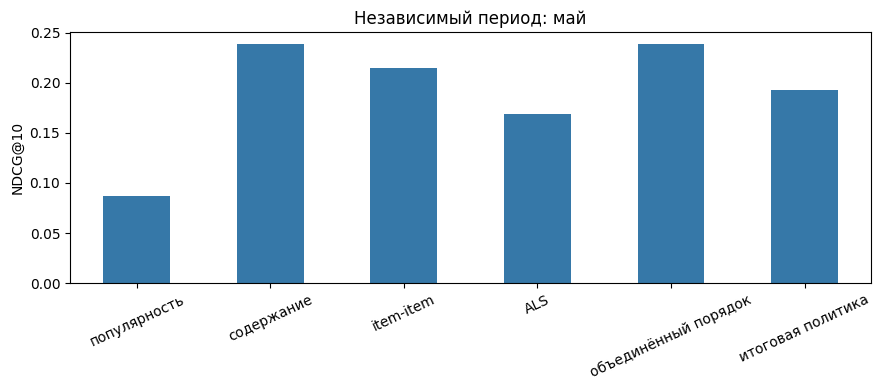

In [14]:
# Шаг М4.05.14 — Единая майская таблица
test_table=pd.DataFrame({name:summarize(score,test_ctx) for name,score in test_bank.items()}).T
test_table.loc["объединённый порядок"]=summarize(test_fused,test_ctx)
test_table.loc["итоговая политика"]=summarize(test_policy_scores,test_ctx)
display(test_table.round(4))
print("Candidate Recall итогового пула:",round(candidate_recall(test_pools,test_ctx).mean(),4))
test_table["NDCG@K"].plot.bar(color="#3678a8",rot=25)
plt.ylabel("NDCG@10");plt.title("Независимый период: май");plt.tight_layout();plt.show()

Bootstrap не используется для изменения веса или политики. Он дополняет отчёт об уже полученном результате. Малые когорты и временные зависимости ограничивают уверенность выводов.

Парное сравнение использует разность результатов одного пользователя у двух алгоритмов. Оно отделяет различие алгоритмов от неодинакового состава аудитории, но не устраняет общие временные зависимости и неполноту журнала.

In [15]:
# Шаг М4.05.15 — Когорты и устойчивость по пользователям
test_detail=evaluate(test_policy_scores,test_ctx)
test_detail["когорта"]=np.where(test_detail.history_size.eq(0),"без истории","с историей")
display(test_detail.groupby("когорта").agg(пользователей=("user_id","size"),
                  Recall=("recall","mean"),NDCG=("ndcg","mean")).round(4))
delta=(evaluate(test_fused,test_ctx).set_index("user_id").ndcg
       -evaluate(test_bank["содержание"],test_ctx).set_index("user_id").ndcg).to_numpy()
rng=np.random.default_rng(23)
bootstrap=rng.choice(delta,size=(1000,len(delta)),replace=True).mean(axis=1)
display(pd.Series({"средняя разница NDCG смеси и содержания":delta.mean(),
                    "нижний 2.5%":np.quantile(bootstrap,.025),
                    "верхний 97.5%":np.quantile(bootstrap,.975)}).to_frame("значение"))

,пользователей,Recall,NDCG
когорта,,,
без истории,10,0.1250,0.0872
с историей,290,0.2155,0.1967


,значение
средняя разница NDCG смеси и содержания,0.0
нижний 2.5%,0.0
верхний 97.5%,0.0


Функция использует уже обученный майский снимок. Для неизвестного пользователя история не придумывается. Поле source описывает фактический путь, а reason объясняет короткую выдачу.

Внешняя функция не должна предполагать, что ключ является допустимым индексом матрицы. Сначала проверяются тип, наличие отображения и история; затем выбирается фактический путь получения оценок.

In [16]:
# Шаг М4.05.16 — Функция выдачи с явным запасным путём
test_similarity=(test_F@test_F.T).toarray()

def recommend(user_id,k=10,blocked_ids=()):
    if not isinstance(k,int) or isinstance(k,bool) or not 1<=k<=20:
        raise ValueError("k должен быть целым числом от 1 до 20")
    if not isinstance(user_id,(int,np.integer)) or isinstance(user_id,bool):
        raise ValueError("user_id должен быть целым идентификатором")
    known=int(user_id) in test_ctx["u_map"]
    row=test_ctx["u_map"].get(int(user_id))
    cold=(not known) or test_ctx["seen"][row].sum()==0
    scores=(reciprocal_ranks(test_ctx["popularity"][None,:],np.zeros((1,len(test_ctx["item_ids"])),dtype=bool))[0]
            if not known else test_fused[row])
    seen=np.zeros(len(scores),dtype=bool) if not known else test_ctx["seen"][row].copy()
    blocked=np.isin(test_ctx["item_ids"],list(blocked_ids))
    allowed=np.flatnonzero(~(seen|blocked))
    if not known:
        original_pool=np.argsort(-test_ctx["popularity"],kind="stable")[:30]
        pool=original_pool[~blocked[original_pool]]
    else:
        pool=np.asarray([i for i in test_pools[row] if not blocked[i]],dtype=int)
    indices=rerank_row(scores,pool,test_ctx["catalog"],test_similarity,k=k)
    result=test_ctx["catalog"].iloc[indices][["product_id","name","category"]].copy()
    result.insert(0,"rank",np.arange(1,len(result)+1))
    model_source="содержание" if weight==1.0 else str(cf_name) if weight==0.0 else "гибрид"
    result["source"]="популярность" if cold else model_source
    reason="короткий список: ограничения или недостаточный пул" if len(result)<k else "полный список"
    return result,{"known_user":known,"cold_user":bool(cold),"requested":k,"returned":len(result),"reason":reason}

Ответ включает данные карточек и диагностические сведения. Они помогают отличить отсутствие истории от ошибки идентификатора или недостатка разрешённых объектов.

Неизвестный пользователь обслуживается без обращения к чужой истории. У результата сохраняется источник, чтобы интерфейс и анализ качества могли отличить персональные рекомендации от общей запасной выдачи.

In [17]:
# Шаг М4.05.17 — Обычный и неизвестный пользователь
normal,normal_info=recommend(1)
unknown,unknown_info=recommend(9999,k=5)
display(normal)
display(pd.DataFrame([normal_info,unknown_info],index=["пользователь 1","неизвестный 9999"]))
display(unknown)
assert unknown.source.eq("популярность").all()

,rank,product_id,name,category,source
114,1,119,Продукты товар 119,Продукты,содержание
19,2,20,Продукты товар 20,Продукты,содержание
14,3,15,Обувь товар 15,Обувь,содержание
42,4,43,Продукты товар 43,Продукты,содержание
64,5,65,Электроника товар 65,Электроника,содержание
1,6,2,Обувь товар 2,Обувь,содержание
132,7,162,Обувь товар 162,Обувь,содержание
15,8,16,Одежда товар 16,Одежда,содержание
78,9,79,Одежда товар 79,Одежда,содержание
2,10,3,Электроника товар 3,Электроника,содержание


,known_user,cold_user,requested,returned,reason
пользователь 1,True,False,10,10,полный список
неизвестный 9999,False,True,5,5,полный список


,rank,product_id,name,category,source
34,1,35,Одежда товар 35,Одежда,популярность
17,2,18,Красота товар 18,Красота,популярность
136,3,168,Дом и сад товар 168,Дом и сад,популярность
85,4,86,Одежда товар 86,Одежда,популярность
102,5,106,Бытовая техника товар 106,Бытовая техника,популярность


Ограничения не обходятся ради заполнения списка. В прикладной системе источник допустимости должен обновляться отдельно от модели, поскольку наличие и запреты могут меняться быстрее пользовательских факторов.

Пустой допустимый набор и неверный параметр имеют разные причины. Первая ситуация возвращает корректную пустую выдачу с диагностикой, вторая отклоняется как некорректный запрос. Запреты сохраняются в обоих случаях.

In [18]:
# Шаг М4.05.18 — Пустой допустимый каталог и неверный запрос
empty,empty_info=recommend(1,blocked_ids=test_ctx["item_ids"])
display(empty)
print(empty_info)
try:
    recommend(1,k=0)
except ValueError as error:
    print("Контролируемый отказ:",error)
assert empty.empty and empty_info["returned"]==0

,rank,product_id,name,category,source


{'known_user': True, 'cold_user': False, 'requested': 10, 'returned': 0, 'reason': 'короткий список: ограничения или недостаточный пул'}
Контролируемый отказ: k должен быть целым числом от 1 до 20


Проверяются свойства, важные для фактического результата. Это целевая проверка учебного конвейера, а не полное тестирование библиотек или инфраструктуры.

Проверка совпадения функции применения с оценёнными списками подтверждает, что в отчёте измерена фактическая выдача. Это особенно важно при наличии отдельного пути для пользователей без истории.

In [19]:
# Шаг М4.05.19 — Проверка всех готовых списков
for u,indices in enumerate(test_lists):
    assert len(indices)==len(set(indices))==10
    assert not test_ctx["seen"][u,indices].any()
    assert test_ctx["catalog"].iloc[indices].category.value_counts().max()<=3
assert np.isfinite(test_fused).all()
print("Проверены уникальность, исключение истории, длина и ограничение категорий.")
for checked_id in [1,2,300]:
    actual,_=recommend(checked_id)
    expected=test_ctx["item_ids"][test_lists[test_ctx["u_map"][checked_id]]]
    assert actual.product_id.tolist()==expected.tolist()
print("Функция выдачи совпадает с оценёнными списками, включая холодного пользователя.")

Проверены уникальность, исключение истории, длина и ограничение категорий.
Функция выдачи совпадает с оценёнными списками, включая холодного пользователя.


Папка outputs содержит производные результаты. Она не требуется для первоначального изучения: все необходимые входные данные включены в data, а ключевые выводы сохранены непосредственно в ноутбуке.

Экспорт результата и сохранение модели являются разными действиями. Пример CSV показывает конкретный снимок выдачи; для повторного расчёта требуются исходные данные, алгоритмы и согласованные параметры из паспорта.

In [20]:
# Шаг М4.05.20 — Экспорт выдачи и паспорта снимка
output_dir=MODULE_DIR/"outputs"
output_dir.mkdir(exist_ok=True)
export_rows=[]
for user_id in [1,2,3,300,9999]:
    table,info=recommend(user_id)
    table.insert(0,"user_id",user_id)
    export_rows.append(table)
export=pd.concat(export_rows,ignore_index=True)
export.to_csv(output_dir/"recommendations_example.csv",index=False,encoding="utf-8")
manifest={"history_before":"2025-05-01","evaluation_window":"2025-05-01/2025-06-01",
          "synthetic_events":True,"catalog_size":180,"content_half_life":90,
          "knn":knn_params,"als":{"rank":16,"regularization":1.0,"alpha":5.0,"iterations":8,"seed":42},
          "cf_source":str(cf_name),"content_weight":weight,"candidates_per_source":30,
          "relevance_weight":.9,"category_cap":3,"k":10}
(output_dir/"recommendation_manifest.json").write_text(json.dumps(manifest,ensure_ascii=False,indent=2),encoding="utf-8")
display(export.head(8))
print("Сохранены примеры выдачи и паспорт; исходные CSV не изменены.")

,user_id,rank,product_id,name,category,source
0,1,1,119,Продукты товар 119,Продукты,содержание
1,1,2,20,Продукты товар 20,Продукты,содержание
2,1,3,15,Обувь товар 15,Обувь,содержание
3,1,4,43,Продукты товар 43,Продукты,содержание
4,1,5,65,Электроника товар 65,Электроника,содержание
5,1,6,2,Обувь товар 2,Обувь,содержание
6,1,7,162,Обувь товар 162,Обувь,содержание
7,1,8,16,Одежда товар 16,Одежда,содержание


Сохранены примеры выдачи и паспорт; исходные CSV не изменены.


Практический результат — сравнение разных рекомендационных подходов, выбранный по validation порядок, отбор кандидатов, контроль разнообразия, тест и функция применения.

Для реального внедрения дополнительно потребуются журнал показов, актуальные правила допустимости, контроль задержки и обновления, оценка разных групп и эксперимент с метриками поведения. Этот набор материалов не объявляет офлайн-выигрыш причинным эффектом.

Источники: [reciprocal rank fusion, SIGIR 2009](https://plg.uwaterloo.ca/~gvcormac/cormacksigir09-rrf.pdf), [MMR, SIGIR 1998](https://www.cs.cmu.edu/~jgc/publication/The_Use_MMR_Diversity_Based_LTMIR_1998.pdf).